In [1]:
import matplotlib
import matplotlib.pylab as pylab
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import scipy.stats as stats
import os

# Exploratory Data Analysis

## 1.1 Basic Description of the Data and Its Characteristics

### Data structure, records and relationships

In [2]:
from pathlib import Path

# CSV files are in ../dataset relative to the src folder
src_dir = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
dataset_dir = src_dir.parent / "dataset"
gateways_df = pd.read_csv(dataset_dir / "gateways.csv", sep=";")
readings_df = pd.read_csv(dataset_dir / "readings.csv", sep="\t")
units_df = pd.read_csv(dataset_dir / "units.csv")
for name, frame in {"gateways": gateways_df, "readings": readings_df, "units": units_df}.items():
    print(name, frame.shape)
    display(frame.head())

gateways (16000, 10)


,firmware_version,idDepot,gatewayId,date_install,vendor,Ipv4,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023/02/11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470.0,Fábio Pinto
1,v2.7.0,94,GW-00001,24 Nov 2018,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406.0,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018/08/20,Schleich,23.152.231.98,-68.7,-9.23071,1022.0,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178.0,Carina Hering
4,v2.7.0,54,GW-00004,21 Sep 2016,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062.0,Chad Salazar


readings (15810, 12)


,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
0,U01837,07 Jan 2023,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,U01444,2023/10/21,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,U01073,"07/17/2023, 05:03:00",3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,U01469,2023-09-02,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,U00271,2023/07/11,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1


units (2000, 7)


,idDepot,last_overhaul,classDuty,serial_number,Manufacturer,hoursService,idUnit
0,69,2016/04/20,H,FN-1865-92664,Correia,19153.0,1
1,85,2022/09/30,H,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,N,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,"12/15/2023, 00:00:00",N,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5


In [3]:
gateways_df.info()
readings_df.info()
units_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   firmware_version  16000 non-null  str    
 1   idDepot           16000 non-null  int64  
 2   gatewayId         16000 non-null  str    
 3   date_install      16000 non-null  str    
 4   vendor            16000 non-null  str    
 5   Ipv4              16000 non-null  str    
 6   dbmSignal         16000 non-null  float64
 7   lon               16000 non-null  float64
 8   idUnit            2000 non-null   float64
 9   Technician        16000 non-null  str    
dtypes: float64(3), int64(1), str(6)
memory usage: 2.2 MB
<class 'pandas.DataFrame'>
RangeIndex: 15810 entries, 0 to 15809
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   idUnit             15810 non-null  str    
 1   ts_cycle           15810 non-null

In [4]:
print(gateways_df.isna().sum())
print(readings_df.isna().sum())
print(units_df.isna().sum())

firmware_version        0
idDepot                 0
gatewayId               0
date_install            0
vendor                  0
Ipv4                    0
dbmSignal               0
lon                     0
idUnit              14000
Technician              0
dtype: int64
idUnit                 0
ts_cycle               0
motorCurrent           0
dpFilter             645
oilTemperature         0
pressureReservoir      0
pressureOil            0
rms_vibration        605
flowmeter              0
humidityIntake       797
current_aux            0
failure                0
dtype: int64
idDepot            0
last_overhaul      0
classDuty          0
serial_number      0
Manufacturer       0
hoursService     100
idUnit             0
dtype: int64


In [5]:
print(gateways_df.duplicated().sum())
print(readings_df.duplicated().sum())
print(units_df.duplicated().sum())

0
234
0


The dataset consists of three CSV files with different separators: gateways.csv (;, 16000 rows × 10 columns, one row per gateway), readings.csv (tab, 15810 × 12, one row per measurement cycle) and units.csv (,, 2000 × 7, one row per compressor unit).

Missing values occur in dpFilter (645), rms_vibration (605), humidityIntake (797) and hoursService (100). readings.csv contains 234 exact duplicate rows.

## Univariate analysis

### Continuous attributes

In [6]:
gateways_df.describe()

,idDepot,dbmSignal,lon,idUnit
count,16000.000000,16000.000000,16000.000000,2000.000000
mean,59.320062,-69.845756,-7.749522,1000.500000
std,34.328884,9.979199,0.890287,577.494589
min,0.000000,-110.000000,-9.299800,1.000000
25%,30.000000,-76.600000,-8.515750,500.750000
50%,59.000000,-69.900000,-7.754480,1000.500000
75%,89.000000,-63.000000,-6.976895,1500.250000
max,119.000000,-40.000000,-6.200200,2000.000000


In [7]:
def describe_numeric(df, col, unit=""):
    s = df[col].dropna()
    
    fig,axes=plt.subplots(1, 2, figsize = (12, 4))
    sns.histplot(s, bins=40, ax=axes[0])
    axes[0].axvline(s.mean(), color="red", linestyle="--", label="mean")
    axes[0].axvline(s.median(), color="black", linestyle=":", label="median")
    axes[0].set_title(f"{col}: histogram")
    axes[0].legend()
    
    stats.probplot(df[col], dist="norm", plot=plt)
    axes[1].set_title(f"{col}: boxplot")
    
    plt.tight_layout()
    plt.show()

    print(f"{col}\nSkewness: ", df[col].skew(), "\nKurtosis: ", df[col].kurtosis())

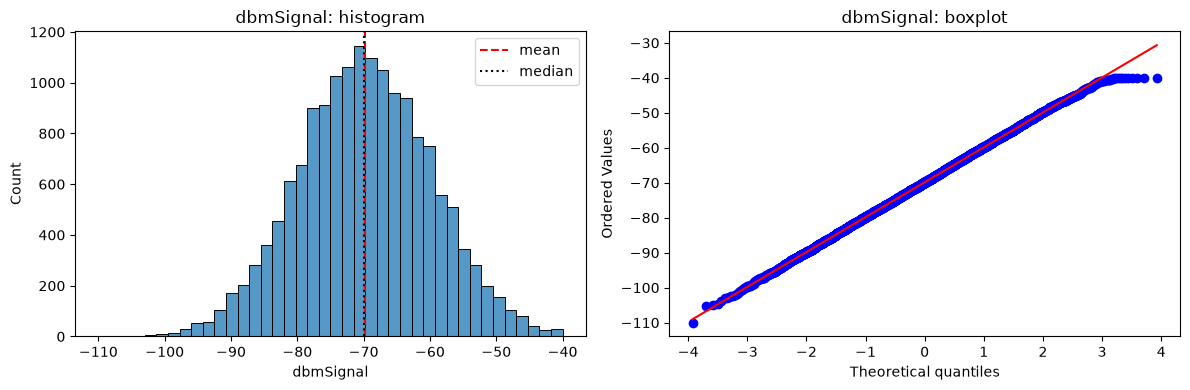

dbmSignal
Skewness:  -0.015231952611536155 
Kurtosis:  -0.08448785444876794


In [8]:
describe_numeric(gateways_df, 'dbmSignal')

**dbmSignal** is approximately normally distributed around −70 dBm *(skew −0.02, excess kurtosis −0.08, mean ≈ median)*. All values fall within −110 to −40 dBm, which is normal for the signal. Also, the maximum values sit exactly at −40, which suggests the sensor’s upper limit.

In [9]:
readings_df.describe()

,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
count,15810.000000,15165.000000,15810.000000,15810.000000,15810.000000,15205.00000,15810.000000,15013.000000,15810.000000,15810.000000
mean,5.347813,24.018677,52.056674,8.693315,3.695502,3.05654,27.975477,52.735388,2.492856,0.121632
std,4.022537,11.102624,57.424465,0.600000,0.563215,1.62775,4.018522,24.643046,0.829407,0.326870
min,0.244370,6.794640,-999.000000,6.500000,1.545990,0.50000,15.000000,10.008960,0.000000,0.000000
25%,3.712815,16.424000,46.847927,8.284840,3.317003,1.92683,25.250510,31.224820,1.930540,0.000000
50%,5.101345,21.376810,55.143305,8.699050,3.694540,2.69787,28.027300,53.001670,2.485760,0.000000
75%,6.664280,28.632630,63.224467,9.099015,4.072695,3.77846,30.717325,74.390130,3.063085,0.000000
max,99.000000,120.000000,95.000000,10.500000,5.618760,14.00000,40.000000,94.993210,5.730790,1.000000


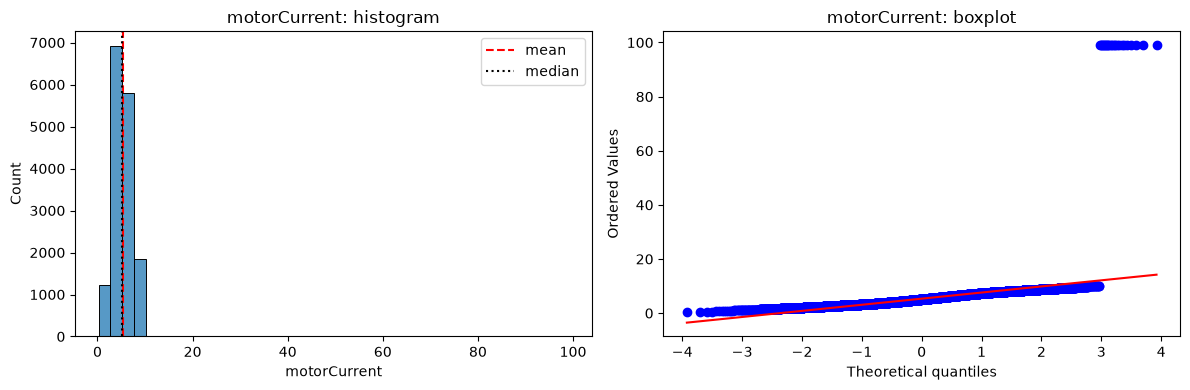

motorCurrent
Skewness:  18.35821522839513 
Kurtosis:  424.71636497403284


In [10]:
describe_numeric(readings_df, 'motorCurrent')

**motorCurrent** is not normally distributed in the raw data *(skew 18.36, excess kurtosis 424.7)*.

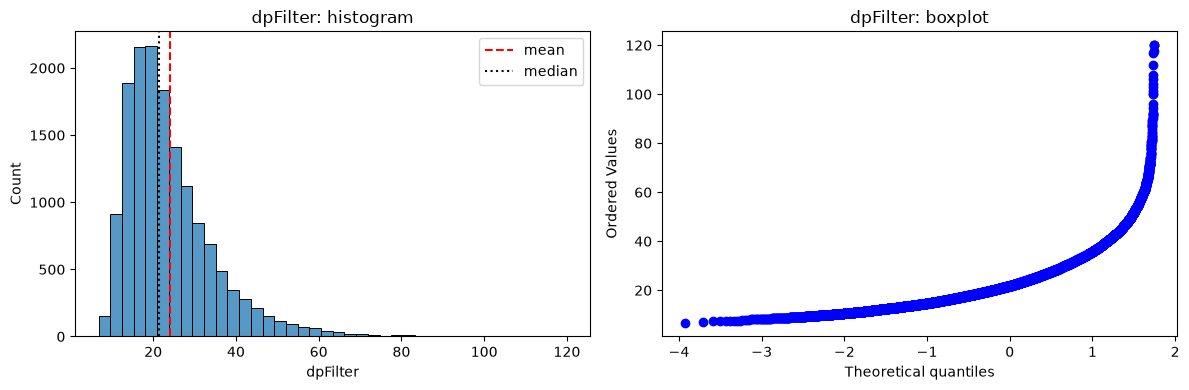

dpFilter
Skewness:  1.9126797347112547 
Kurtosis:  6.6383105487790175


In [11]:
describe_numeric(readings_df, 'dpFilter')

**dpFilter** is not normally distributed and it is right-skewed *(skew 1.91, excess kurtosis 6.64)*. 

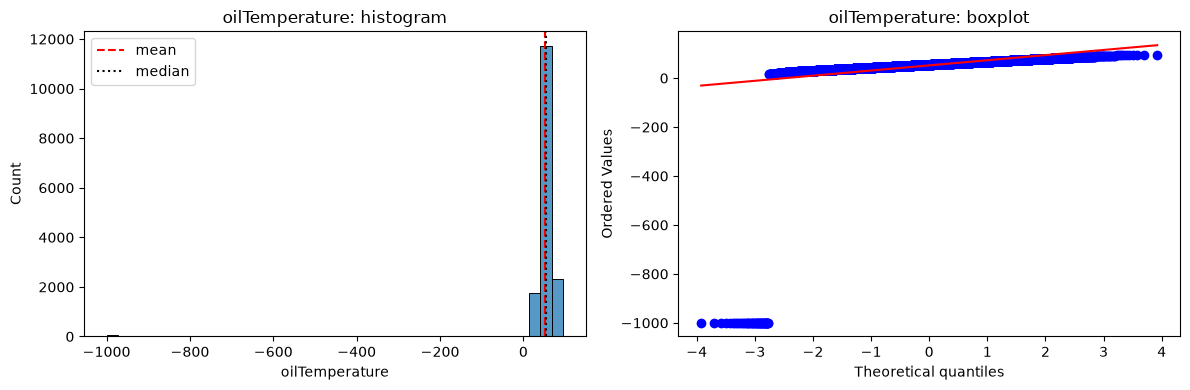

oilTemperature
Skewness:  -17.449419441898 
Kurtosis:  316.5931245360613


In [12]:
describe_numeric(readings_df, 'oilTemperature')

**oilTemperature** is not normally distributed in the raw data *(skew −17.45, excess kurtosis 316.6)*.  

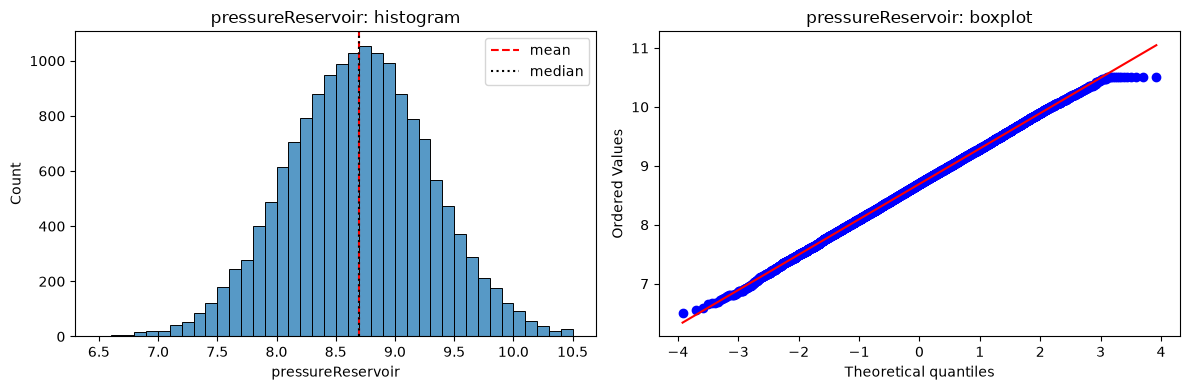

pressureReservoir
Skewness:  -0.02729741340095718 
Kurtosis:  -0.050608791808986364


In [13]:
describe_numeric(readings_df, 'pressureReservoir')

**pressureReservoir** is approximately normally distributed around 8.7 bar *(skew −0.03, excess kurtosis −0.05)*. Values lie between 6.5 and 10.5 bar. 15 readings sit exactly at the maximum of 10.5, which suggests the sensor’s upper limit.

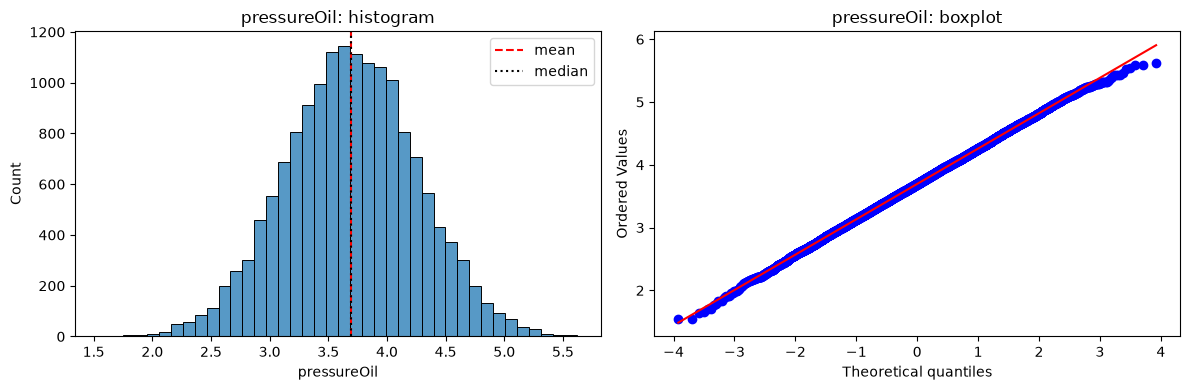

pressureOil
Skewness:  -0.025271051684024923 
Kurtosis:  -0.024289339089729634


In [14]:
describe_numeric(readings_df, 'pressureOil')

**pressureOil** is approximately normally distributed around 3.7 bar *(skew −0.03, excess kurtosis −0.02)*. All values fall within 1.55 to 5.62 bar, with no extreme values.

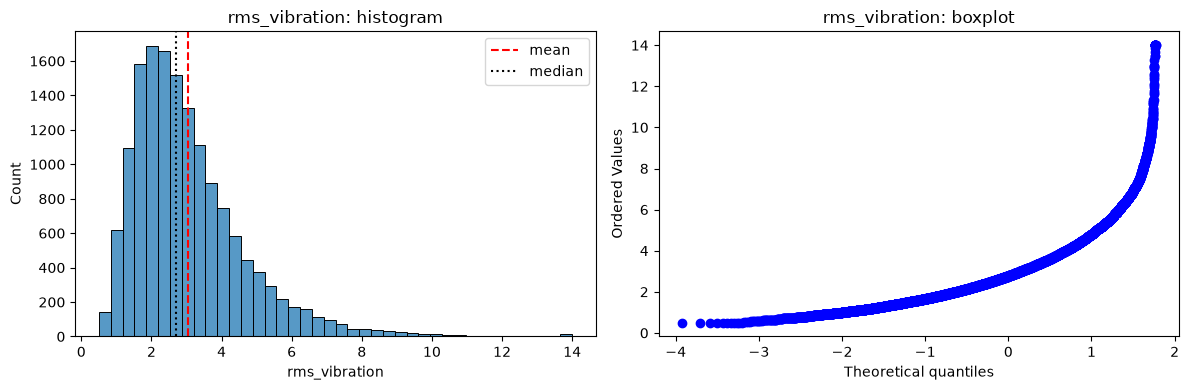

rms_vibration
Skewness:  1.7030889748528248 
Kurtosis:  5.05269557433335


In [15]:
describe_numeric(readings_df, 'rms_vibration')

**rms_vibration** is not normally distributed and it is right-skewed *(skew 1.70, excess kurtosis 5.05)*. Values are bounded by 0.5 and 14.0, and both limits occur repeatedly (10 and 14 times), which suggests the sensor’s measurement range.

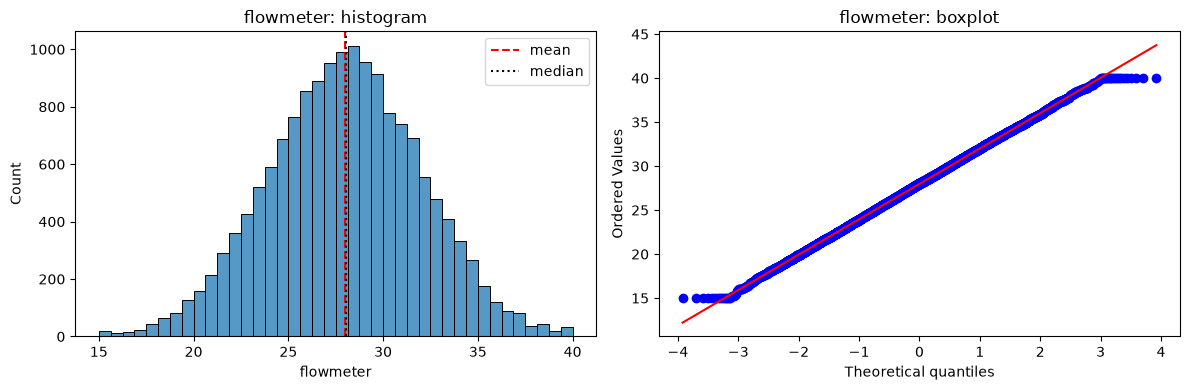

flowmeter
Skewness:  -0.028680880920081427 
Kurtosis:  -0.08375994947218546


In [16]:
describe_numeric(readings_df, 'flowmeter')

**flowmeter** is approximately normally distributed around 28 *(skew -0.03, excess kurtosis -0.08)*. Values are cut off exactly at 15 and 40, so the sensor clips readings outside this range.

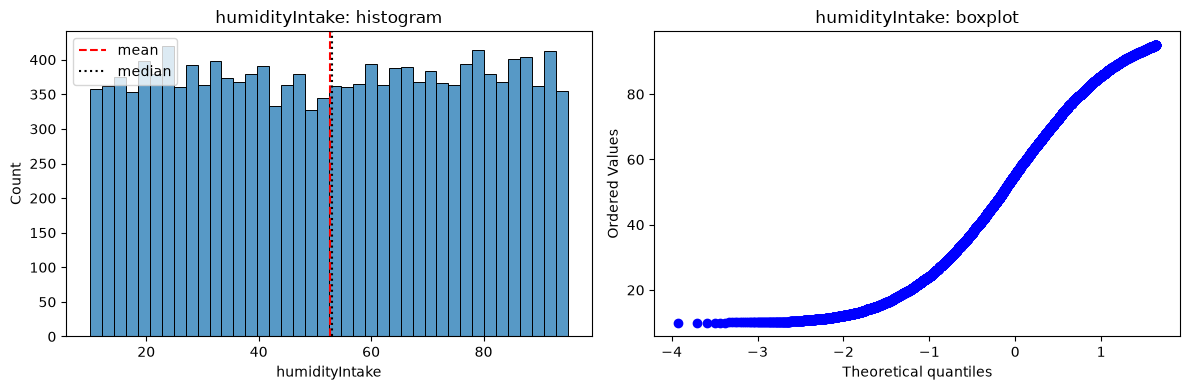

humidityIntake
Skewness:  -0.01044712634425088 
Kurtosis:  -1.224298425947802


In [17]:
describe_numeric(readings_df, 'humidityIntake')

**humidityIntake** is not normally distributed *(skew -0.01, excess kurtosis -1.22)*. The values are spread evenly between 10 and 95%. All values lie within the valid range for relative humidity.

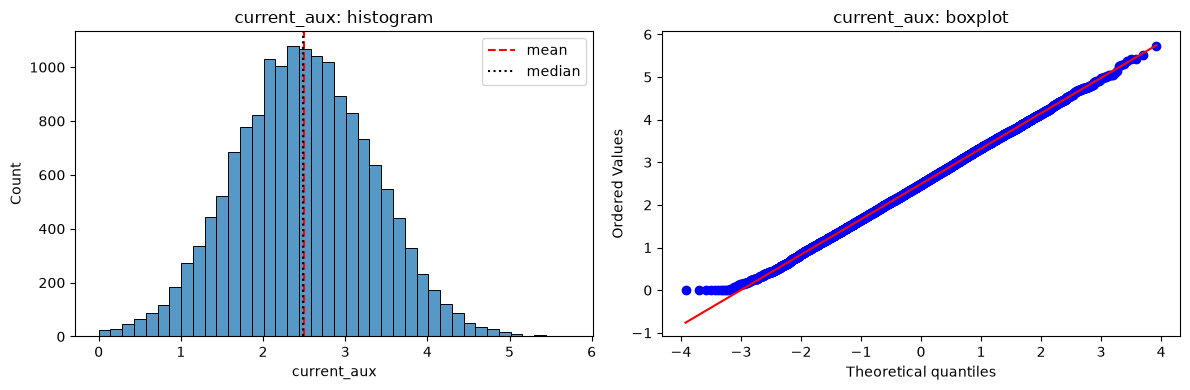

current_aux
Skewness:  0.019802817719925432 
Kurtosis:  -0.10608588185291934


In [18]:
describe_numeric(readings_df, 'current_aux')

**current_aux** is approximately normally distributed around 2.5 *(skew 0.02, excess kurtosis -0.11)*. Values range from 0 to <6.

In [19]:
units_df.describe()

,idDepot,hoursService,idUnit
count,2000.00000,1900.000000,2000.000000
mean,55.44350,14440.480895,1000.500000
std,34.47994,8641.125647,577.494589
min,0.00000,2069.100000,1.000000
25%,26.00000,8349.150000,500.750000
50%,53.00000,12460.300000,1000.500000
75%,84.00000,17864.700000,1500.250000
max,119.00000,45000.000000,2000.000000


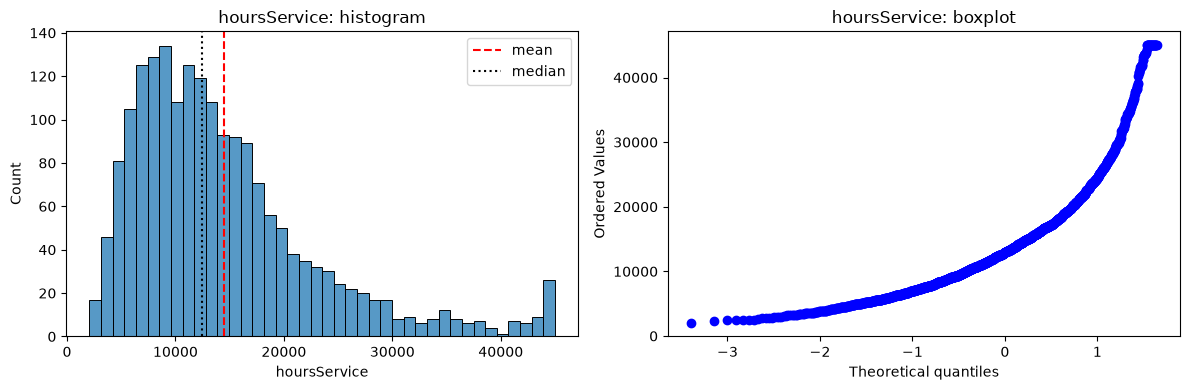

hoursService
Skewness:  1.4378743217112822 
Kurtosis:  2.216836496439879


In [20]:
describe_numeric(units_df, 'hoursService')

**hoursService** is not normally distributed and it is right-skewed *(skew 1.44, excess kurtosis 2.22)*.

### Categorical attributes

In [21]:
gateways_df["firmware_version"].value_counts()

firmware_version
v3.4.1    5544
v2.7.0    5415
v1.2.5    5041
Name: count, dtype: int64

In [22]:
readings_df["failure"].value_counts()

failure
0    13887
1     1923
Name: count, dtype: int64

In [23]:
print(units_df["classDuty"].value_counts())
print(units_df["Manufacturer"].value_counts())

classDuty
L           251
light       249
1           231
normal      170
heavy       159
2           156
med         154
H           153
3           140
N           131
 L           30
 1           29
 H           27
 light       25
 3           23
 N           20
 2           16
 med         15
 heavy       11
 normal      10
Name: count, dtype: int64
Manufacturer
Faria                         98
Pacheco                       76
Seifert Seifert GbR           69
Smith Group                   62
Nette                         61
Mayo LLC                      60
Campos                        59
Stey                          59
Cohen-Randolph                58
Murray PLC                    57
Gunpf                         57
Abbott, Duncan and Barnes     55
Munoz, Parsons and Coleman    54
Kraus Harloff GmbH            53
Simões Lda.                   53
Lourenço Pereira e Filhos     52
Silva Soares S.A.             52
Klein-Chavez                  51
Lourenço                      50
Wulf

## Bivariate analysis

### Continuous - continuous

In [24]:
sensor_columns=["motorCurrent","dpFilter","oilTemperature","pressureReservoir","pressureOil", "rms_vibration","flowmeter","humidityIntake","current_aux"]

eda_readings=readings_df.copy()
eda_readings["idUnit"]=pd.to_numeric(eda_readings["idUnit"].str.replace(r"^U","",regex=True),errors="coerce").astype("Int64")
eda_readings["ts_cycle"]=pd.to_datetime(eda_readings["ts_cycle"],format="mixed",errors="coerce")

eda_readings["oilTemperature"]=eda_readings["oilTemperature"].mask(eda_readings["oilTemperature"].eq(-999))
eda_readings["motorCurrent"]=eda_readings["motorCurrent"].mask(eda_readings["motorCurrent"].eq(99))

eda_units=units_df.copy()
eda_units["classDuty"]=eda_units["classDuty"].str.strip().str.lower().replace({"h":"heavy","l":"light","n":"normal"})
eda_units["last_overhaul"]=pd.to_datetime(eda_units["last_overhaul"],format="mixed",errors="coerce")

eda_gateways=gateways_df.loc[gateways_df["idUnit"].notna(),["idUnit","firmware_version","vendor","dbmSignal"]].copy()
eda_gateways["idUnit"]=eda_gateways["idUnit"].astype("Int64")

eda_df=(eda_readings.merge(eda_units,on="idUnit",how="inner",validate="many_to_one").merge(eda_gateways,on="idUnit",how="left",validate="many_to_one"))
eda_df["days_since_overhaul"]=(eda_df["ts_cycle"]-eda_df["last_overhaul"]).dt.days

unit_level=eda_df.drop_duplicates("idUnit")

continuous_columns=sensor_columns+["hoursService","days_since_overhaul","dbmSignal"]
categorical_columns=["classDuty","Manufacturer","firmware_version","vendor"]
eda_df.shape

(15655, 22)

Before the analysis, the readings are joined with units and the linked gateways on idUnit. The sentinels (-999, 99) are masked, and days_since_overhaul is derived as the difference between the reading date and the last overhaul.

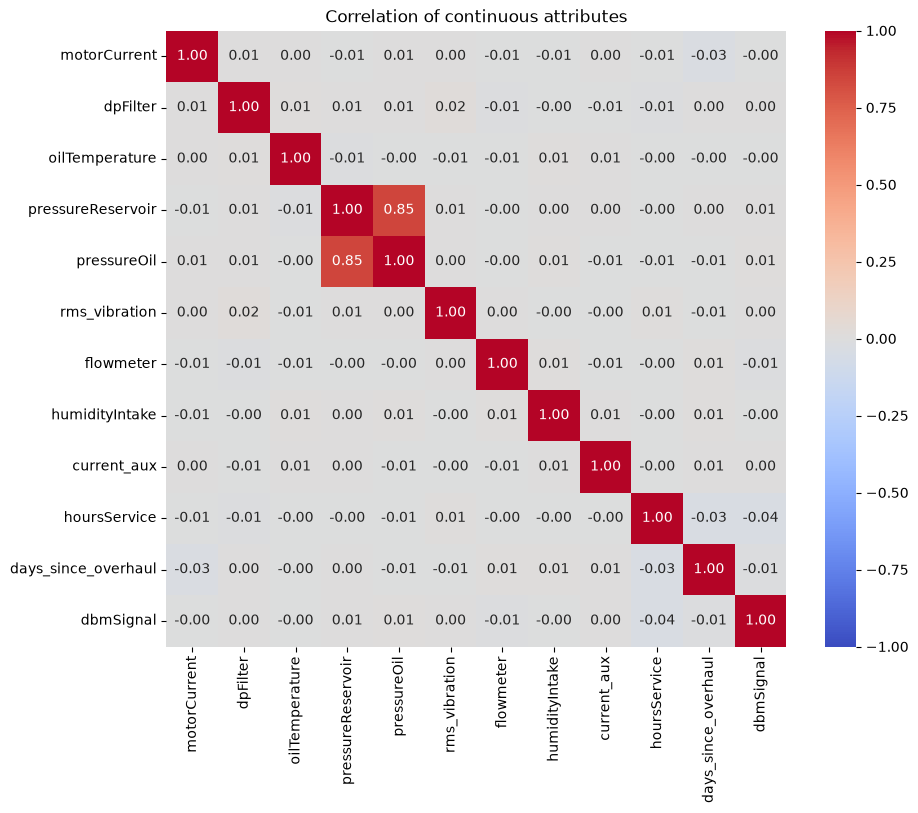

In [25]:
fig,axes=plt.subplots(figsize=(10,8))
sns.heatmap(eda_df[continuous_columns].corr(method="pearson"),annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,ax=axes)
axes.set_title("Correlation of continuous attributes")

plt.show()

Only one pair of continuous attributes is dependent: pressureOil and pressureReservoir, with r = 0.85. All other pairs have |r| ≤ 0.04, so the sensors and unit attributes are practically independent of each other.

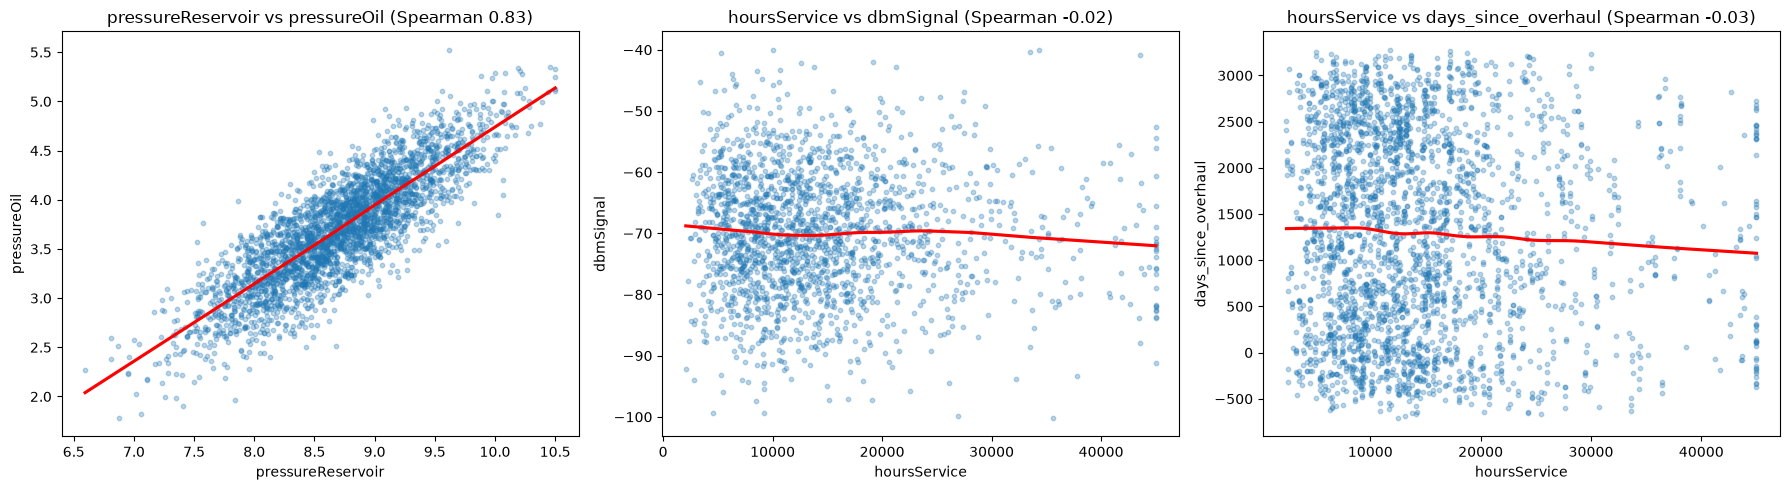

In [26]:
plot_pairs=[("pressureReservoir","pressureOil",eda_df),("hoursService","dbmSignal",unit_level),("hoursService","days_since_overhaul",eda_df)]

fig,axes=plt.subplots(1,3,figsize=(18,5))
for ax,(x,y,frame) in zip(axes,plot_pairs):
    sample=frame.sample(min(3000,len(frame)),random_state=42)
    sns.regplot(data=sample,x=x,y=y,ax=ax,lowess=True,scatter_kws={"alpha":0.3,"s":10},line_kws={"color":"red"})
    ax.set_title(f"{x} vs {y} (Spearman {frame[x].corr(frame[y],method='spearman'):.2f})")
    
plt.tight_layout()
plt.show()

pressureOil rises linearly with pressureReservoir, so the two attributes carry largely the same information. One of them can be dropped, or both can be combined into a single feature.

dbmSignal vs hoursService and days_since_overhaul vs hoursService show flat clouds with no trend, which confirms that these attributes are independent

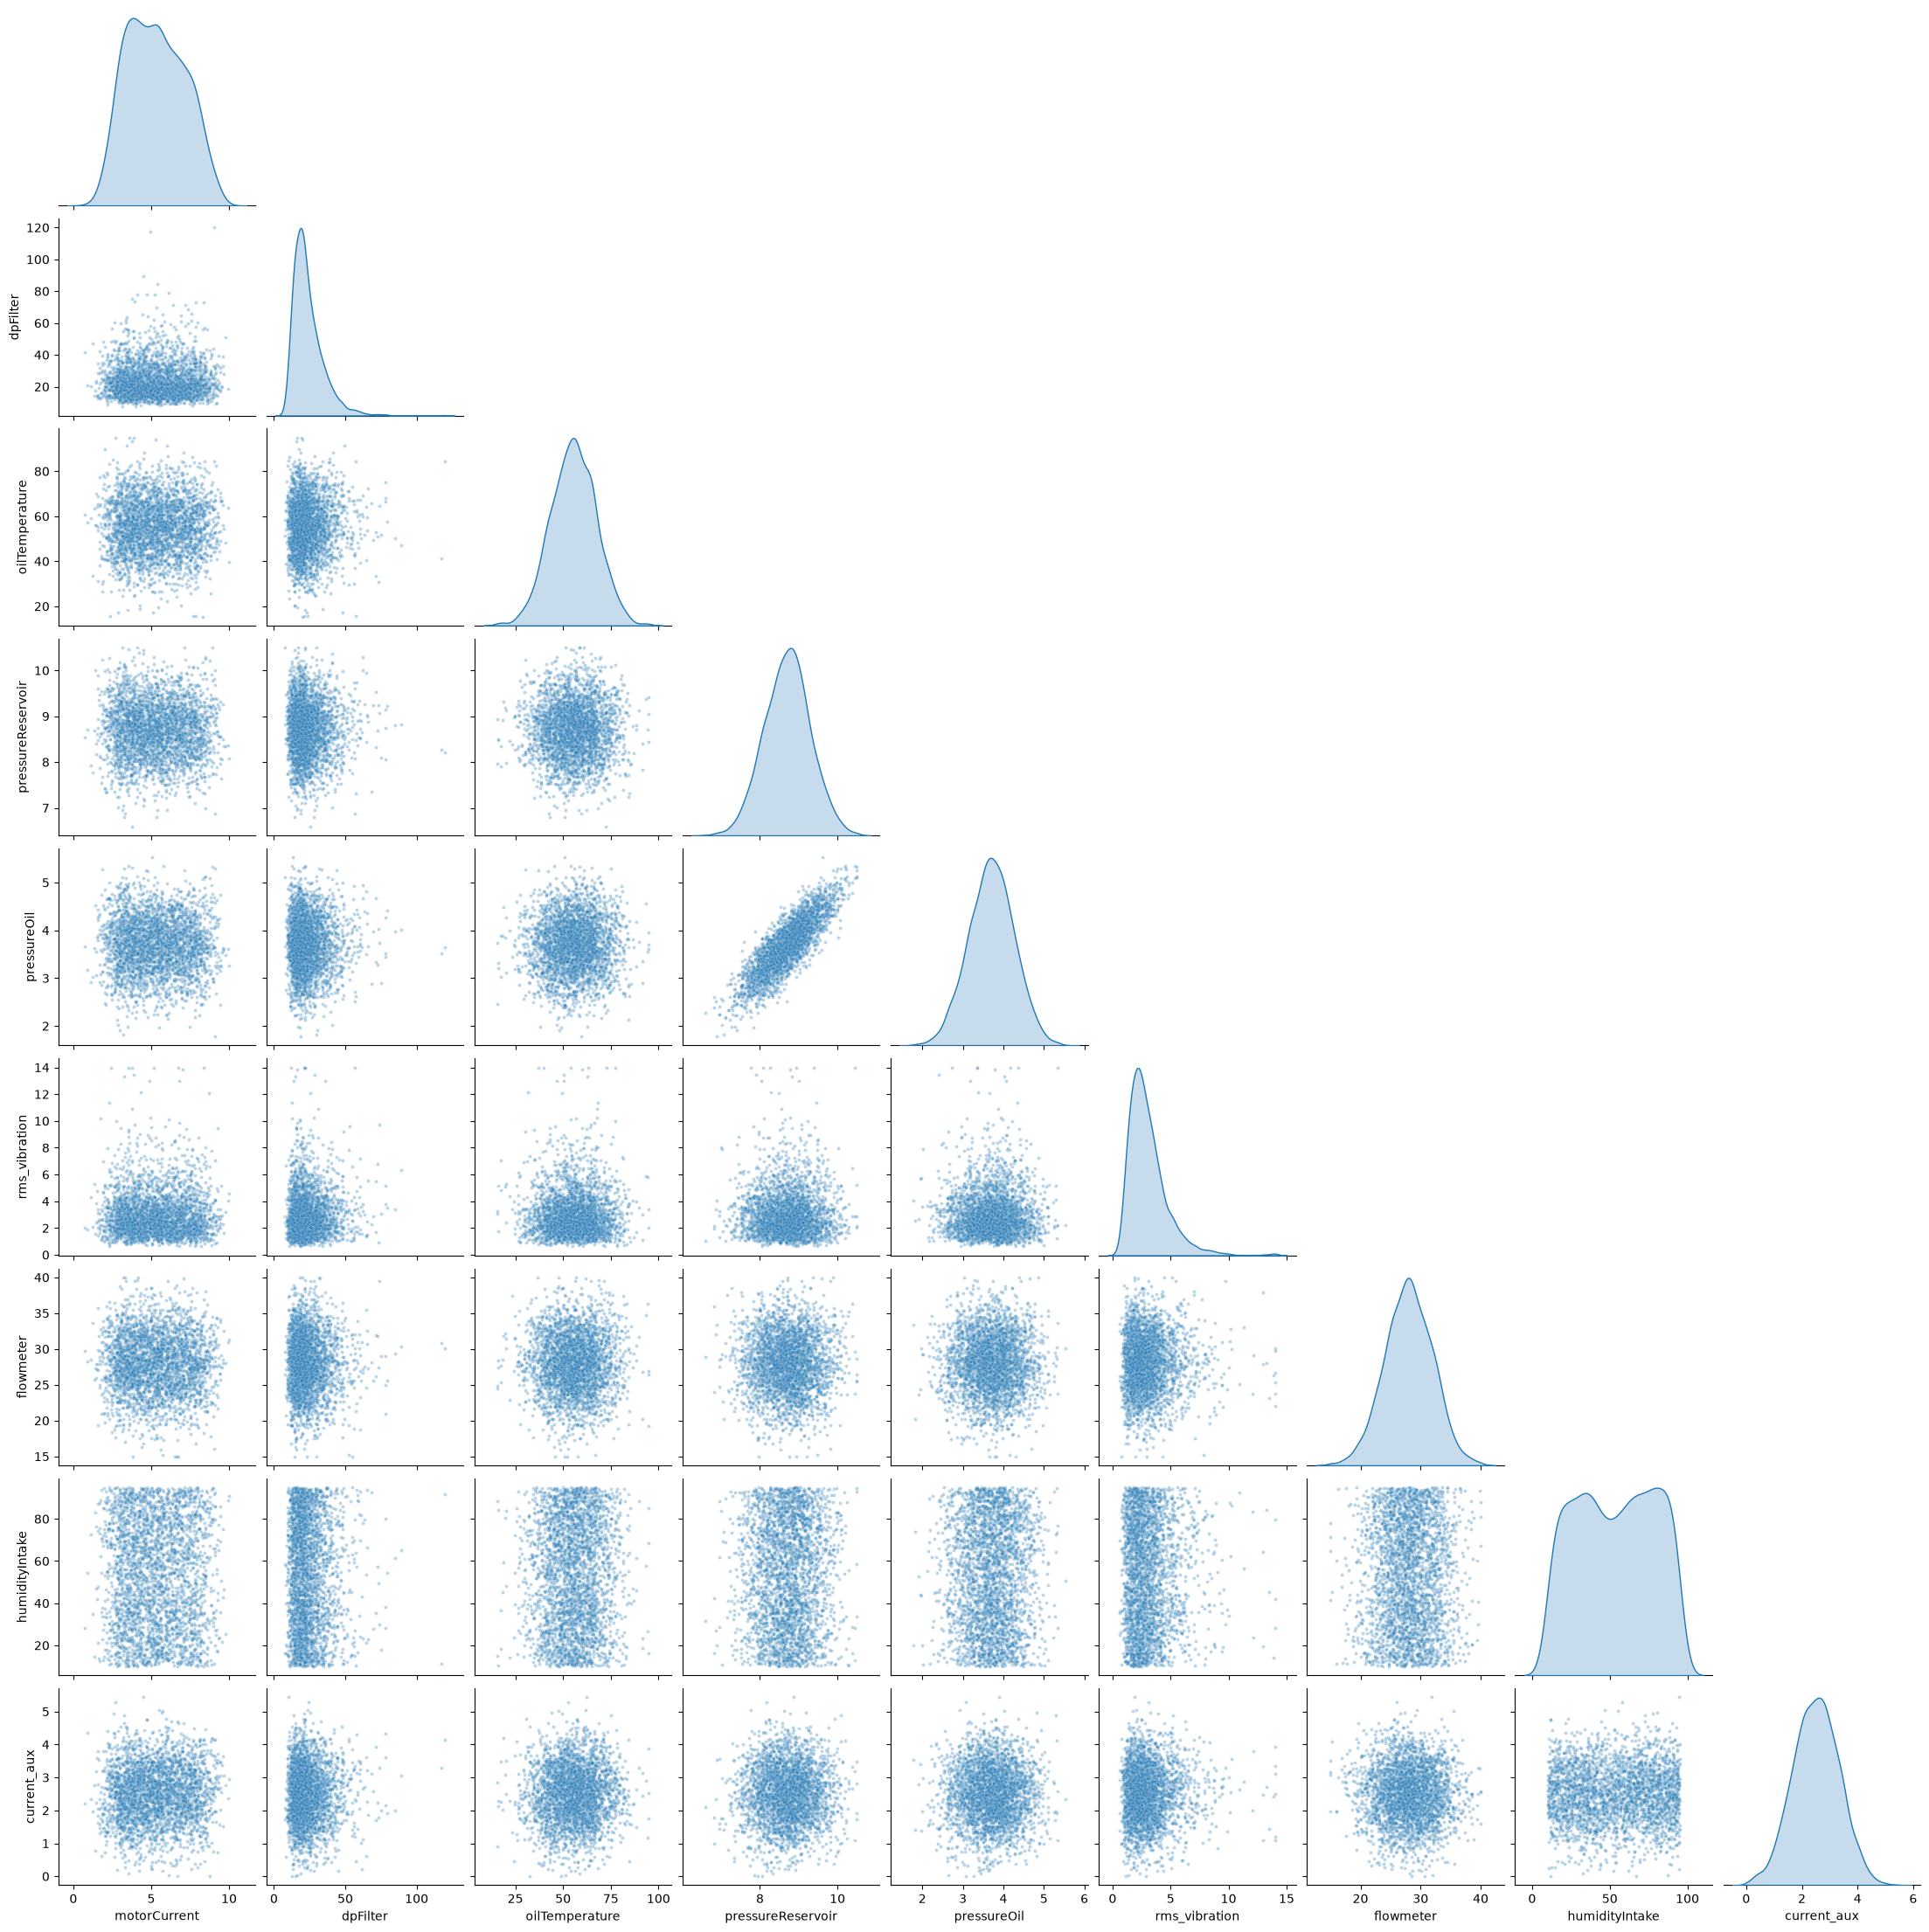

In [27]:
sns.pairplot(eda_df[sensor_columns].sample(3000,random_state=42),corner=True,diag_kind="kde",plot_kws={"alpha":0.3,"s":8})
plt.show()

The pairplot confirms the correlation matrix. The diagonal shows the skew of dpFilter and rms_vibration. Apart from the pressure pair, no non-linear patterns or clusters appear between the sensors.

### Continuous - categorical

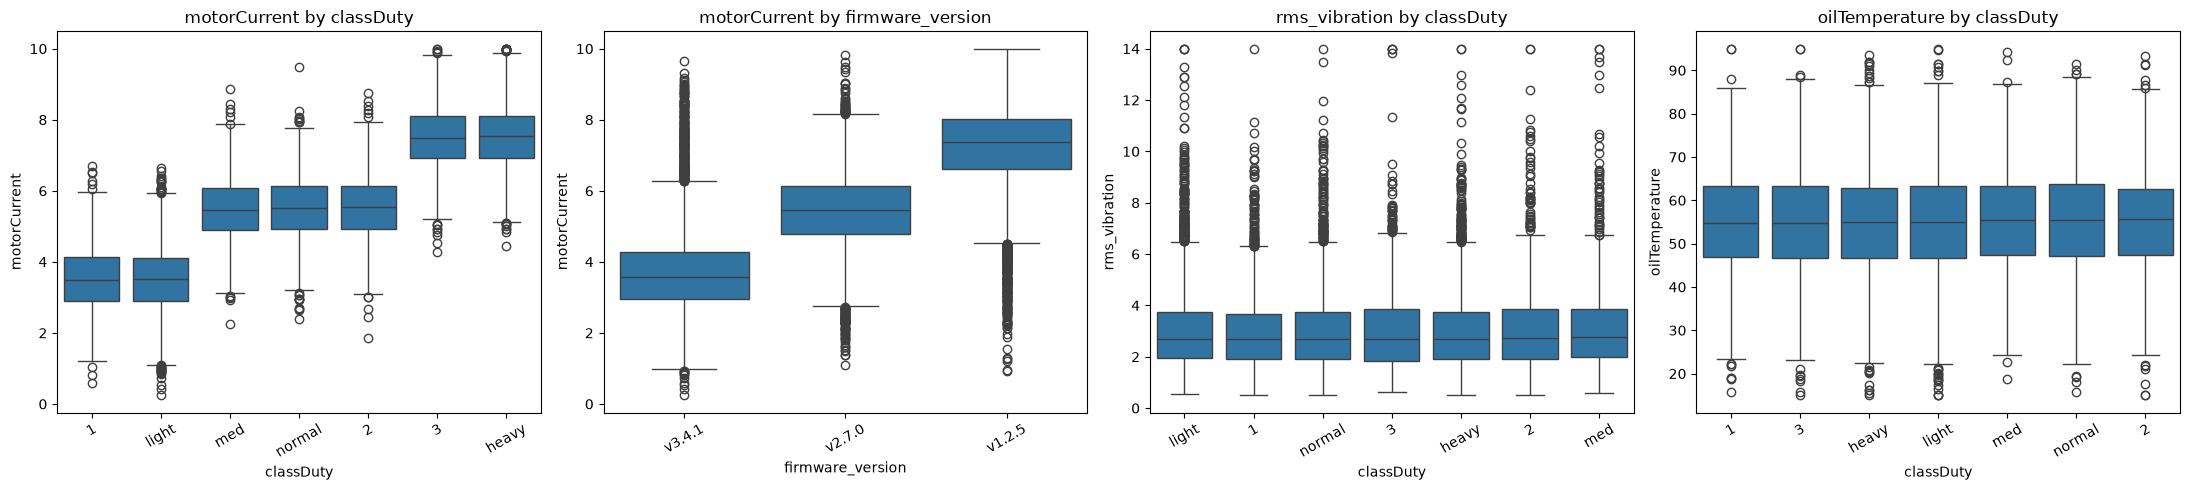

In [28]:
plot_pairs=[("classDuty","motorCurrent"),("firmware_version","motorCurrent"),("classDuty","rms_vibration"),("classDuty","oilTemperature")]
fig,axes=plt.subplots(1,4,figsize=(22,5))

for ax,(cat,num) in zip(axes,plot_pairs):
    order=eda_df.groupby(cat)[num].median().sort_values().index
    sns.boxplot(data=eda_df,x=cat,y=num,order=order,ax=ax)
    ax.set_title(f"{num} by {cat}")
    ax.tick_params(axis="x",rotation=30)
    
plt.tight_layout()
plt.show()

motorCurrent depends strongly on classDuty. firmware_version also seems to affect motorCurrent. rms_vibration and oilTemperature do not differ between duty classes.

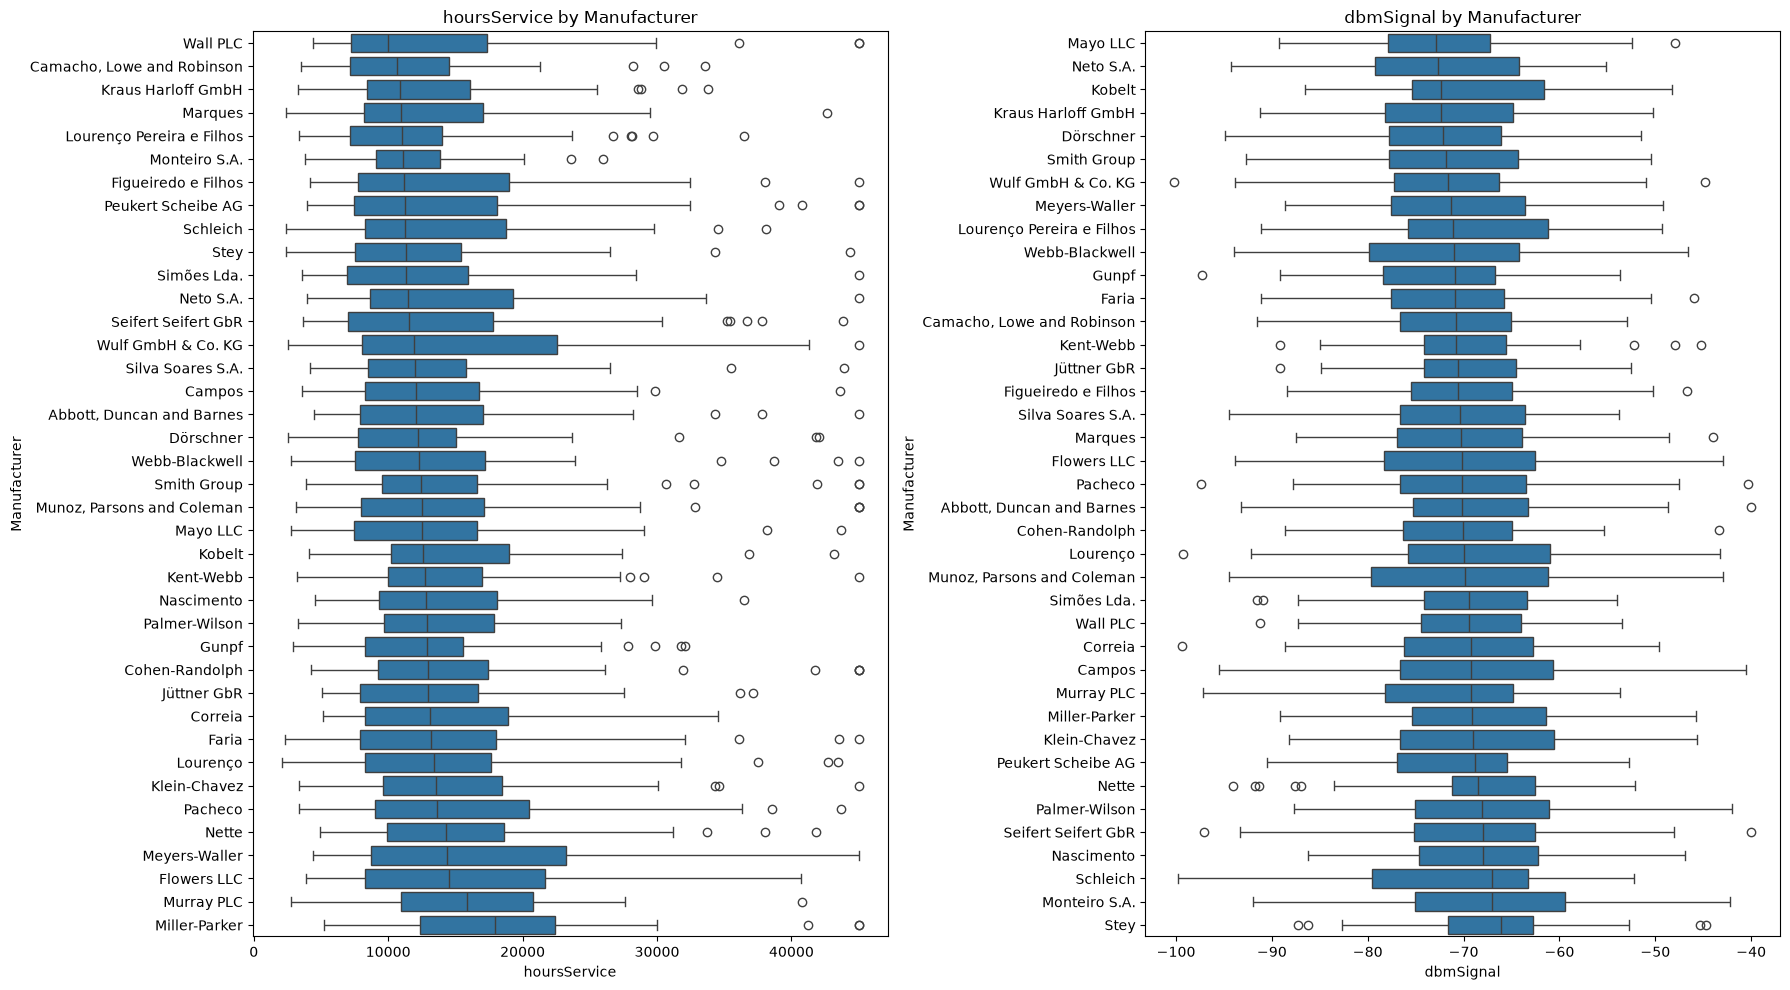

In [29]:
fig,axes=plt.subplots(1,2,figsize=(18,10))

for ax,num in zip(axes,["hoursService","dbmSignal"]):
    order=unit_level.groupby("Manufacturer")[num].median().sort_values().index
    sns.boxplot(data=unit_level,y="Manufacturer",x=num,order=order,ax=ax)
    ax.set_title(f"{num} by Manufacturer")
    
plt.tight_layout()
plt.show()

These plots use one row per unit, because hoursService and dbmSignal are constant within a unit. Neither attribute differs between manufacturers, so the manufacturer does not determine unit age or the gateway’s signal quality.

### Categorical - categorical

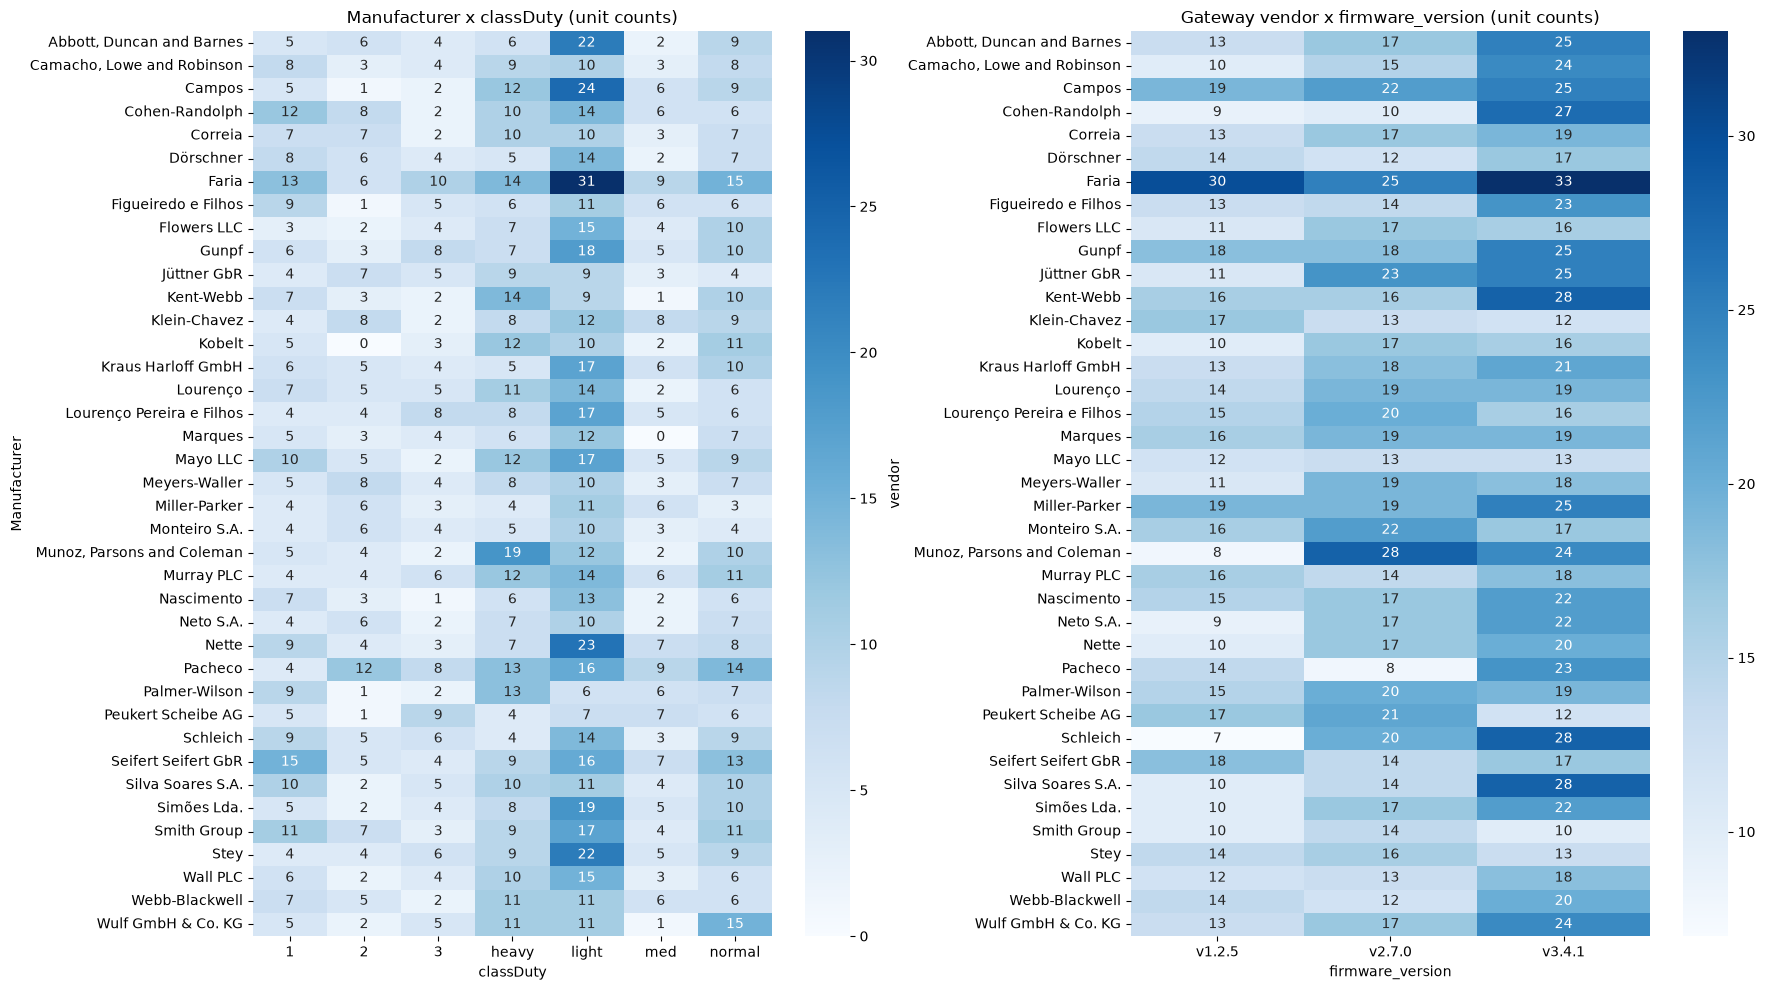

In [30]:
fig,axes=plt.subplots(1,2,figsize=(18,10))
sns.heatmap(pd.crosstab(unit_level["Manufacturer"],unit_level["classDuty"]),annot=True,fmt="d",cmap="Blues",ax=axes[0])
axes[0].set_title("Manufacturer x classDuty (unit counts)")

sns.heatmap(pd.crosstab(unit_level["vendor"],unit_level["firmware_version"]),annot=True,fmt="d",cmap="Blues",ax=axes[1])
axes[1].set_title("Gateway vendor x firmware_version (unit counts)")

plt.tight_layout()
plt.show()

The units are spread evenly over the combinations of Manufacturer and classDuty, and of gateway vendor and firmware_version.

## Pairwise data analysis between the predicted variable

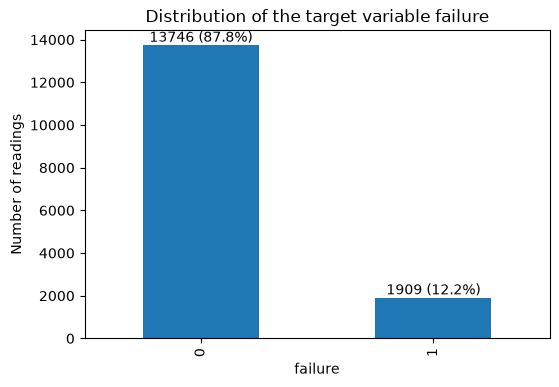

In [31]:
failure_counts=eda_df["failure"].value_counts().sort_index()
fig,ax=plt.subplots(figsize=(6,4))
failure_counts.plot.bar(ax=ax)

for i,v in enumerate(failure_counts):
    ax.text(i,v,f"{v} ({v/failure_counts.sum():.1%})",ha="center",va="bottom")
    
ax.set_title("Distribution of the target variable failure")
ax.set_xlabel("failure")
ax.set_ylabel("Number of readings")
plt.show()

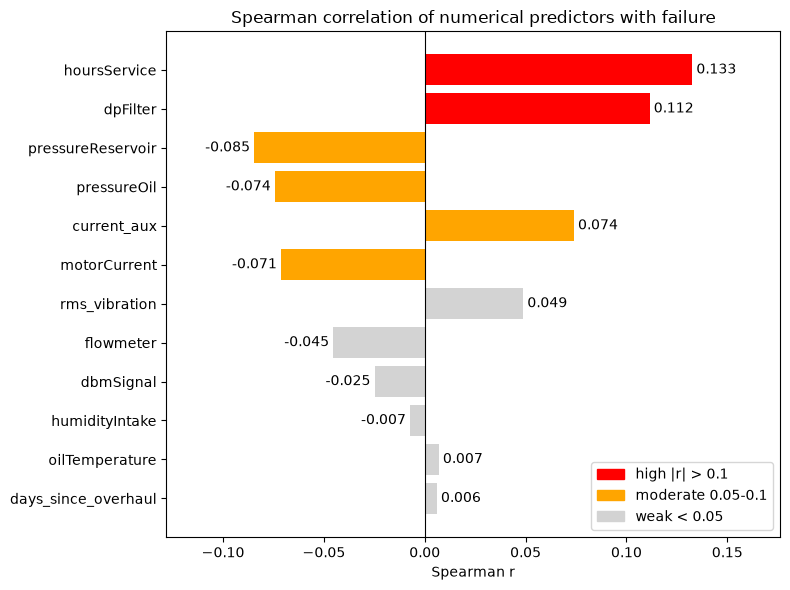

In [32]:
target_corr=eda_df[continuous_columns].corrwith(eda_df["failure"],method="spearman")
target_corr=target_corr.reindex(target_corr.abs().sort_values().index)

strength=pd.cut(target_corr.abs(),bins=[0,0.05,0.1,1],labels=["weak","moderate","high"],include_lowest=True)
colors=strength.map({"weak":"lightgrey","moderate":"orange","high":"red"}).astype(str)

fig,ax=plt.subplots(figsize=(8,6))
ax.barh(target_corr.index,target_corr.values,color=colors)
ax.axvline(0,color="black",linewidth=0.8)

for y,v in enumerate(target_corr.values):
    ax.text(v,y,f" {v:.3f} ",va="center",ha="left" if v>=0 else "right")
    
ax.margins(x=0.2)
handles=[plt.Rectangle((0,0),1,1,color=c) for c in ["red","orange","lightgrey"]]
ax.legend(handles,["high |r| > 0.1","moderate 0.05-0.1","weak < 0.05"],loc="lower right")
ax.set_title("Spearman correlation of numerical predictors with failure")
ax.set_xlabel("Spearman r")
plt.tight_layout()
plt.show()

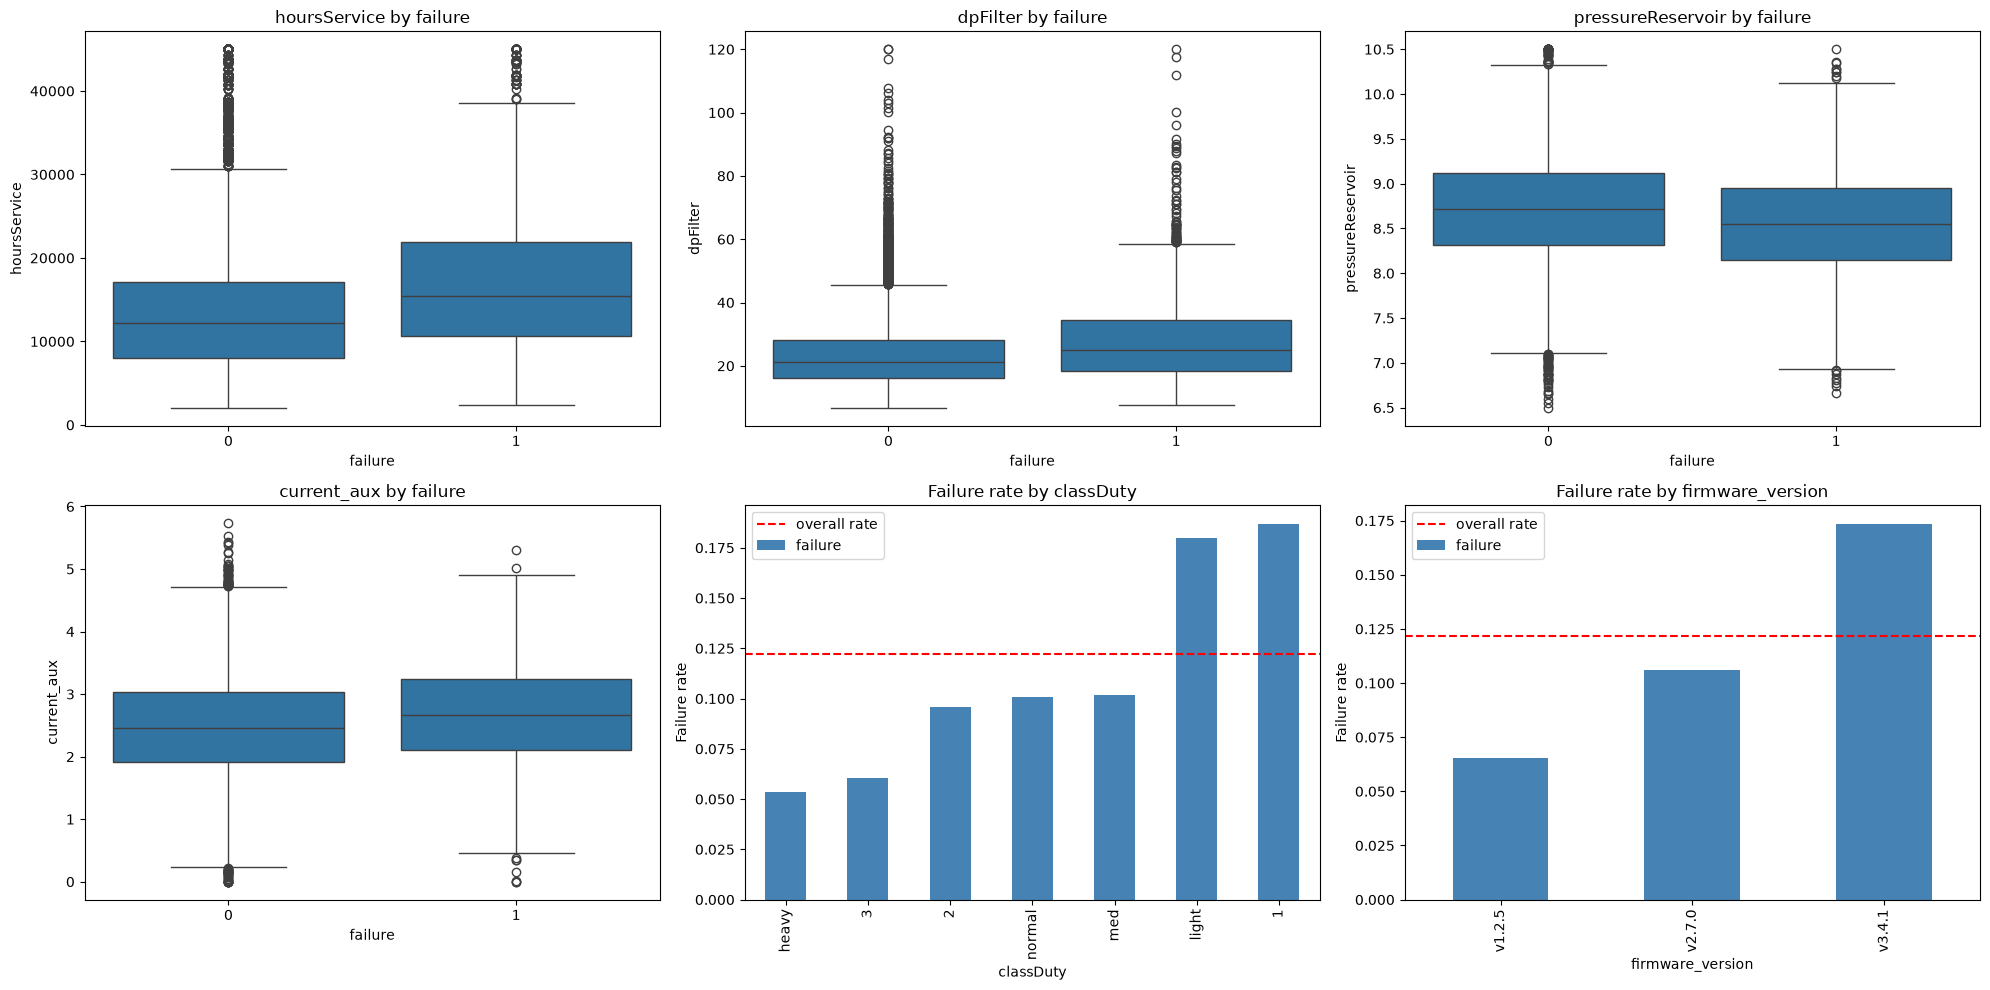

In [33]:
fig,axes=plt.subplots(2,3,figsize=(20,10))

for ax,col in zip(axes.flat[:4],["hoursService","dpFilter","pressureReservoir","current_aux"]):
    sns.boxplot(data=eda_df,x="failure",y=col,ax=ax)
    ax.set_title(f"{col} by failure")
    
for ax,cat in zip(axes.flat[4:],["classDuty","firmware_version"]):
    rate=eda_df.groupby(cat)["failure"].mean().sort_values()
    
    rate.plot.bar(ax=ax,color="steelblue")
    ax.axhline(eda_df["failure"].mean(),color="red",linestyle="--",label="overall rate")
    ax.set_title(f"Failure rate by {cat}")
    ax.set_ylabel("Failure rate")
    ax.legend()
    
plt.tight_layout()
plt.show()

The target failure is binary, with about 12% positives. For numeric attributes we use Spearman correlation with the target, because several sensors are skewed. For categorical attributes we compare the failure rate in each category against the overall rate (red line). With a rare binary target, correlations are small by nature, so the colour thresholds are 0.1 and 0.05 instead of the usual 0.5 and 0.7

**High:** hoursService and dpFilter. Units with more operating hours and a more clogged filter fail more often.

**Moderate:** pressureReservoir, pressureOil and motorCurrent  are lower before a failure. current_aux is higher before a failure. pressureOil and pressureReservoir are strongly correlated with each other, so they carry largely the same information.

**Weak:** rms_vibration, flowmeter, dbmSignal, humidityIntake, oilTemperature, days_since_overhaul.

## 1.2 Problems, data integration, and data cleaning

The prediction target is `failure`, recorded for each measurement cycle. Keep one row per reading and attach unit and gateway metadata through `idUnit`.

### Normalize formats and remove redundant records

Reading IDs such as `U01837` and unit ID `1837` represent the same unit. Parse mixed dates into datetime values, date-only values have no known time and are represented at midnight. Unify the clear letter/word duty variants, leaving `med` and undocumented numeric codes separate

In [34]:
tables = {"gateways": gateways_df, "readings": readings_df, "units": units_df}
date_columns = {"gateways": "date_install", "readings": "ts_cycle", "units": "last_overhaul"}
normalized = {}

for name, table in tables.items():
    
    # remove exact duplicate rows so repeated copies do not bias the analysis.
    frame = table.drop_duplicates().copy()
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
        
    for column in [c for c in ["idUnit", "idDepot"] if c in frame]:
        key_text = frame[column].astype("string")
        
        if name == "readings" and column == "idUnit": 
            # remove the U prefix to match the integer IDs in the metadata tables
            key_text = key_text.str.replace(r"^U", "", regex=True)
            
        numeric = pd.to_numeric(key_text, errors="coerce")
        valid = numeric.notna() & np.isfinite(numeric) & numeric.ge(0) & numeric.mod(1).eq(0)
        
        # replace invalid IDs with missing value, zero is a valid depot ID
        frame[column] = numeric.where(valid).astype("Int64")
        
    frame[date_columns[name]] = pd.to_datetime(frame[date_columns[name]], format="mixed", errors="coerce")
    
    if name == "units":
        frame["classDuty"] = frame["classDuty"].str.lower().replace({"h": "heavy", "l": "light", "n": "normal"})
        
    # remove full-row duplicates that become identical after format normalization.
    normalized[name] = frame.drop_duplicates().copy()

gateways_clean = normalized["gateways"]
readings_clean = normalized["readings"]
units_clean = normalized["units"]
display(gateways_clean)
display(readings_clean)
display(units_clean)

,firmware_version,idDepot,gatewayId,date_install,vendor,Ipv4,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023-02-11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470,Fábio Pinto
1,v2.7.0,94,GW-00001,2018-11-24,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018-08-20,Schleich,23.152.231.98,-68.7,-9.23071,1022,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178,Carina Hering
4,v2.7.0,54,GW-00004,2016-09-21,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062,Chad Salazar
...,...,...,...,...,...,...,...,...,...,...
15995,v3.4.1,99,GW-15995,2024-06-11,Simões Lda.,223.105.80.99,-71.4,-6.50930,<NA>,Meghan Patel
15996,v2.7.0,4,GW-15996,2022-07-16,Webb-Blackwell,188.156.69.66,-61.9,-7.13180,<NA>,Brian Coelho
15997,v2.7.0,30,GW-15997,2024-05-06,Palmer-Wilson,244.143.197.78,-68.6,-7.38450,<NA>,André da Almeida
15998,v3.4.1,68,GW-15998,2020-07-26,Kraus Harloff GmbH,238.5.110.95,-68.8,-7.79738,<NA>,Dr. Adriana Cichorius B.Eng.


,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
0,1837,2023-01-07 00:00:00,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,1444,2023-10-21 00:00:00,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,1073,2023-07-17 05:03:00,3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,1469,2023-09-02 00:00:00,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,271,2023-07-11 00:00:00,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1
...,...,...,...,...,...,...,...,...,...,...,...,...
15571,1715,2023-10-03 00:00:00,8.10634,23.75623,38.55659,8.46866,4.01351,NaN,20.45578,81.22487,3.44488,0
15572,1355,2023-07-19 06:48:00,6.25650,22.18533,43.43464,8.57624,3.80081,2.38926,32.42021,21.72667,2.03999,0
15573,971,2023-11-12 14:06:00,7.93083,28.02206,65.17459,9.23116,3.58476,4.64216,30.77456,55.17802,1.72297,0
15574,159,2023-11-29 00:00:00,5.95949,39.84336,65.75819,8.57829,3.73022,2.46270,27.35111,58.52541,2.79068,0


,idDepot,last_overhaul,classDuty,serial_number,Manufacturer,hoursService,idUnit
0,69,2016-04-20,heavy,FN-1865-92664,Correia,19153.0,1
1,85,2022-09-30,heavy,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,normal,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,2023-12-15,normal,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5
...,...,...,...,...,...,...,...
1995,73,2024-07-28,light,GI-2985-30885,Klein-Chavez,3345.0,1996
1996,76,2023-07-01,light,OG-0205-65156,Mayo LLC,5703.6,1997
1997,58,2021-03-21,normal,FA-1584-67680,Webb-Blackwell,11374.7,1998
1998,105,2021-09-15,1,JS-9450-43578,Pacheco,7251.0,1999


### Abnormal measurements

Replace invalid measurements with missing values. Current values of `99` are suspicious but are not confirmed errors

In [35]:
sensor_columns = ["motorCurrent", "dpFilter", "oilTemperature", "pressureReservoir",
                  "pressureOil", "rms_vibration", "flowmeter", "humidityIntake", "current_aux"]

for column in sensor_columns:
    values = readings_clean[column]
    invalid = values.notna() & ~np.isfinite(values)
    
    if column == "oilTemperature":
        invalid |= values.eq(-999)
        
    if column == "humidityIntake":
        invalid |= values.notna() & ~values.between(0, 100)
        
    # remove non-finite values, the -999 temperature sentinel, and impossible humidity values
    readings_clean.loc[invalid, column] = np.nan

invalid_hours = units_clean["hoursService"].lt(0) | (units_clean["hoursService"].notna() & ~np.isfinite(units_clean["hoursService"]))

# remove negative or infinite service hours by replacing them with missing values
units_clean.loc[invalid_hours, "hoursService"] = np.nan
invalid_longitude = gateways_clean["lon"].notna() & ~gateways_clean["lon"].between(-180, 180)

# remove coordinates outside the valid longitude range.
gateways_clean.loc[invalid_longitude, "lon"] = np.nan
display(gateways_clean)

,firmware_version,idDepot,gatewayId,date_install,vendor,Ipv4,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023-02-11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470,Fábio Pinto
1,v2.7.0,94,GW-00001,2018-11-24,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018-08-20,Schleich,23.152.231.98,-68.7,-9.23071,1022,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178,Carina Hering
4,v2.7.0,54,GW-00004,2016-09-21,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062,Chad Salazar
...,...,...,...,...,...,...,...,...,...,...
15995,v3.4.1,99,GW-15995,2024-06-11,Simões Lda.,223.105.80.99,-71.4,-6.50930,<NA>,Meghan Patel
15996,v2.7.0,4,GW-15996,2022-07-16,Webb-Blackwell,188.156.69.66,-61.9,-7.13180,<NA>,Brian Coelho
15997,v2.7.0,30,GW-15997,2024-05-06,Palmer-Wilson,244.143.197.78,-68.6,-7.38450,<NA>,André da Almeida
15998,v3.4.1,68,GW-15998,2020-07-26,Kraus Harloff GmbH,238.5.110.95,-68.8,-7.79738,<NA>,Dr. Adriana Cichorius B.Eng.


### Integrate the tables

Use many-to-one joins to prevent row multiplication. Exclude unresolved reading IDs, invalid labels, and conflicting labels for the same unit/date. 

In [36]:
cycle_keys = ["idUnit", "ts_cycle"]
conflicting_labels = readings_clean.groupby(cycle_keys, dropna=False)["failure"].transform("nunique").gt(1)
valid_readings = readings_clean["idUnit"].notna() & readings_clean["ts_cycle"].notna()
valid_readings &= readings_clean["failure"].isin([0, 1]) & ~conflicting_labels

# remove readings with invalid IDs/dates/labels or unresolved contradictory cycle labels
readings_for_merge = readings_clean.loc[valid_readings].copy()

# exclude unassigned gateways from the unit join; a depot does not identify a unique unit
linked_gateways = gateways_clean.loc[gateways_clean["idUnit"].notna()].copy()
gateway_metadata = linked_gateways.rename(columns={c: f"gateway_{c}" for c in linked_gateways if c != "idUnit"})
integrated_df = readings_for_merge.merge(units_clean, on="idUnit", how="left", validate="many_to_one", indicator="unit_match")

# remove readings whose IDs have no matching unit metadata
cleaned_df = integrated_df.loc[integrated_df["unit_match"].eq("both")].copy()

# remove the temporary merge indicator once unmatched readings have been excluded
cleaned_df = cleaned_df.drop(columns="unit_match")
cleaned_df = cleaned_df.merge(gateway_metadata, on="idUnit", how="left", validate="many_to_one")
display(cleaned_df)

,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,...,hoursService,gateway_firmware_version,gateway_idDepot,gateway_gatewayId,gateway_date_install,gateway_vendor,gateway_Ipv4,gateway_dbmSignal,gateway_lon,gateway_Technician
0,1837,2023-01-07 00:00:00,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,...,15380.2,v2.7.0,48,GW-01390,2020-03-02,Figueiredo e Filhos,164.97.196.111,-76.8,-8.39000,Ahmed Bachmann
1,1444,2023-10-21 00:00:00,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,...,17358.0,v3.4.1,89,GW-00829,2020-04-23,Murray PLC,211.187.30.38,-80.2,-8.31471,Gustavo Andrade
2,1073,2023-07-17 05:03:00,3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,...,19389.9,v2.7.0,26,GW-01692,2018-01-14,Miller-Parker,14.144.63.149,-55.7,-8.43676,Henry Salinas
3,1469,2023-09-02 00:00:00,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,...,3564.2,v3.4.1,39,GW-01796,2019-01-01,"Camacho, Lowe and Robinson",244.177.113.187,-56.5,-7.76988,Inês Matos
4,271,2023-07-11 00:00:00,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,...,45000.0,v2.7.0,19,GW-01375,2017-12-06,Marques,21.85.158.5,-75.7,-6.85225,Ricardo Carvalho
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15392,1715,2023-10-03 00:00:00,8.10634,23.75623,38.55659,8.46866,4.01351,NaN,20.45578,81.22487,...,23388.9,v2.7.0,109,GW-01956,2017-02-18,Faria,152.230.240.2,-68.9,-8.73926,Sofia Neves
15393,1355,2023-07-19 06:48:00,6.25650,22.18533,43.43464,8.57624,3.80081,2.38926,32.42021,21.72667,...,10316.3,v3.4.1,103,GW-01605,2019-12-21,Seifert Seifert GbR,88.190.198.114,-86.8,-8.20242,Destiny Wilson
15394,971,2023-11-12 14:06:00,7.93083,28.02206,65.17459,9.23116,3.58476,4.64216,30.77456,55.17802,...,8590.6,v1.2.5,91,GW-00660,2022-09-26,Nette,238.111.51.140,-69.0,-8.88391,Andrea Willis
15395,159,2023-11-29 00:00:00,5.95949,39.84336,65.75819,8.57829,3.73022,2.46270,27.35111,58.52541,...,10430.7,v2.7.0,40,GW-01689,2015-04-29,Wulf GmbH & Co. KG,92.102.66.43,-82.8,-7.41809,Mr. Jeremy Davis


### Compare two outlier treatments

Apply IQR removal and 5th/95th percentile clipping. Missing values alone are not outliers. Keep plausible extremes in `cleaned_df`, since they may carry a failure signal

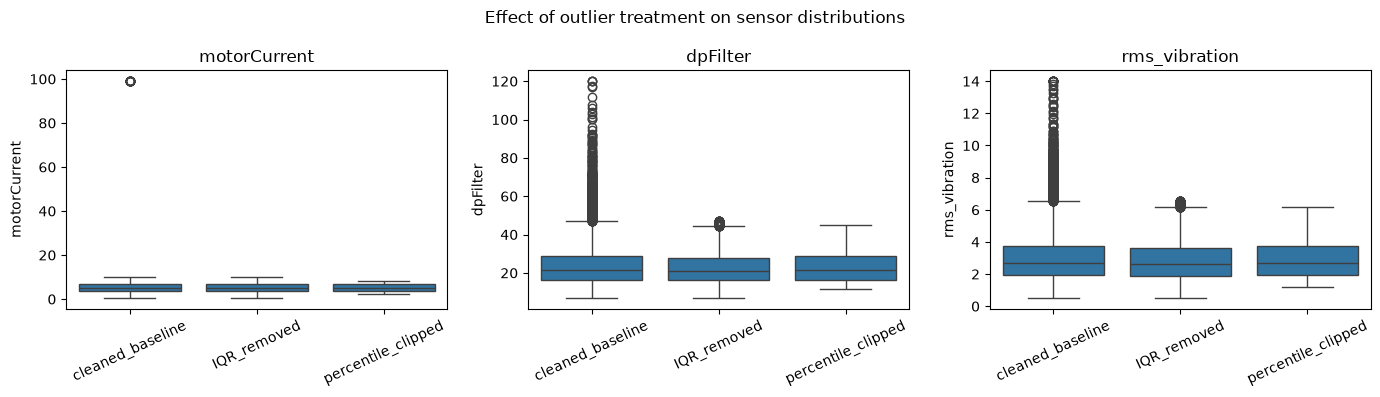

In [37]:
sensor_values = cleaned_df[sensor_columns]
q1, q3 = sensor_values.quantile(0.25), sensor_values.quantile(0.75)
iqr = q3 - q1
iqr_lower, iqr_upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_flags = sensor_values.lt(iqr_lower, axis="columns") | sensor_values.gt(iqr_upper, axis="columns")

# remove a reading from this alternative if any observed sensor exceeds its IQR fences
iqr_removed_df = cleaned_df.loc[~iqr_flags.any(axis=1)].copy()

p05, p95 = sensor_values.quantile(0.05), sensor_values.quantile(0.95)
clipped_df = cleaned_df.copy()

# replace extreme sensor values with the 5th/95th percentile boundaries; keep rows and missing values
clipped_df[sensor_columns] = sensor_values.clip(lower=p05, upper=p95, axis="columns")

variants = {"cleaned_baseline": cleaned_df, "IQR_removed": iqr_removed_df, "percentile_clipped": clipped_df}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, column in zip(axes, ["motorCurrent", "dpFilter", "rms_vibration"]):
    plot_data = pd.concat([frame[[column]].assign(treatment=name) for name, frame in variants.items()], ignore_index=True)
    sns.boxplot(data=plot_data, x="treatment", y=column, ax=ax)
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel("")
    ax.set_title(column)
    
fig.suptitle("Effect of outlier treatment on sensor distributions")
plt.tight_layout()
plt.show()

## 1.3 Hypothesis testing and statistical power

- **Vibration:** Hypothesis 1: the mean within-unit difference in `rms_vibration` between failure and non-failure states is zero
- Hypothesis 2: it differs from zero
- **Oil pressure:** the same H1/H2 for `pressureOil`

average observed readings within each unit/state, then apply two-sided paired t-tests to units observed in both states, giving each unit equal weight and avoiding treating its cycles as independent samples

use `cleaned_df` without outliers removed. tests assume independent units and approximately normal sampling distributions of mean differences, supported by the large number of pairs. Missing values may bias results, particularly for vibration

apply Bonferroni correction for two tests at overall alpha = 0.05 and report matching 97.5% confidence intervals

check power against a specified paired effect d = 0.2, measured in standard deviations of within-unit differences, with an 80% target. this is an example sensitivity threshold

methods: [paired t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html), [paired-test power](https://www.statsmodels.org/stable/generated/statsmodels.stats.power.TTestPower.html)

In [39]:
from statsmodels.stats.power import TTestPower

alpha = 0.05
test_alpha = alpha / 2
target_d = 0.2
power_model = TTestPower()
results = []

for sensor in ["rms_vibration", "pressureOil"]:
    paired = cleaned_df.groupby(["idUnit", "failure"])[sensor].mean().unstack()
    
    # exclude units without observed measurements in both states for this sensor
    paired = paired.dropna(subset=[0, 1])
    difference = paired[1] - paired[0]
    test = stats.ttest_rel(paired[1], paired[0], alternative="two-sided")
    interval = test.confidence_interval(confidence_level=1 - test_alpha)
    power = power_model.power(effect_size=target_d, nobs=len(paired), alpha=test_alpha, alternative="two-sided")
    
    results.append({"sensor": sensor, "units": len(paired),
                    "mean_no_failure": paired[0].mean(), "mean_failure": paired[1].mean(),
                    "difference": difference.mean(),
                    "ci_97.5%": f"[{interval.low:.3f}, {interval.high:.3f}]",
                    "paired_d": difference.mean() / difference.std(ddof=1),
                    "p_adjusted": min(1.0, 2 * test.pvalue),
                    "power_d_0.2": power,
                    "effect_d_0.2": target_d * difference.std(ddof=1)})

hypothesis_results = pd.DataFrame(results).set_index("sensor")
display(hypothesis_results.round(4))

for sensor, row in hypothesis_results.iterrows():
    decision = "reject H0" if row["p_adjusted"] < alpha else "do not reject H0"
    direction = "higher" if row["difference"] > 0 else "lower"
    support = "sufficient" if row["power_d_0.2"] >= 0.8 else "insufficient"
    
    print(f"{sensor}: {decision}; failure mean is {direction} by {abs(row['difference']):.3f}; "f"power for d=0.2 is {row['power_d_0.2']:.1%} ({support})")

,units,mean_no_failure,mean_failure,difference,ci_97.5%,paired_d,p_adjusted,power_d_0.2,effect_d_0.2
sensor,,,,,,,,,
rms_vibration,1002,3.0282,3.3227,0.2945,"[0.171, 0.418]",0.1686,0.0,1.0,0.3494
pressureOil,1114,3.7168,3.5875,-0.1293,"[-0.168, -0.090]",-0.2225,0.0,1.0,0.1162


rms_vibration: reject H0; failure mean is higher by 0.295; power for d=0.2 is 100.0% (sufficient)
pressureOil: reject H0; failure mean is lower by 0.129; power for d=0.2 is 100.0% (sufficient)


These associations apply to units with observed measurements in both states. They do not establish causation or future prediction accuracy

Leave both sensors as candidate predictors and evaluate them during model validation. Power describes detection of the specified d = 0.2 under the paired-test assumptions, not every smaller effect